(user_guide_optimization_pso)=

# Particle Swarm Optimization (PSO)

📖 {ref}`Particle Swarm Optimization API Reference <api_optimization_PSO>`

**Particle Swarm Optimization (PSO)** (Kennedy & Eberhart, 1995) is a metaheuristic inspired by the collective motion of bird flocks and fish schools. Rather than breeding new candidates as a genetic algorithm does, PSO keeps a fixed set of candidates, the *particles*, and moves them around the search space. Each particle remembers the best place it has visited so far and learns from the best places its neighbours have found. Over time the swarm gathers in good regions without any gradient information.

The implementation, {py:class}`~sigmaepsilon.math.optimize.pso.ParticleSwarmOptimization`, follows the same usage pattern as the [genetic algorithms](bga.ipynb) and [ACO](aco.ipynb) of the library: you pass an objective and box `ranges`, call `solve`, and get back the champion. It can also return **several distinct solutions** at once, one per basin of attraction, which is what this page focuses on after the basics.

## How it works

Every particle $i$ has a position $\mathbf{x}_i$, which is a candidate solution, and a velocity $\mathbf{v}_i$. It also remembers its *personal best* $\mathbf{p}_i$, the best position it has visited so far. In every iteration, all particles first update their velocities and then move:

$$
\mathbf{v}_i \leftarrow w\,\mathbf{v}_i
+ c_1\,\mathbf{r}_1 \odot (\mathbf{p}_i - \mathbf{x}_i)
+ c_2\,\mathbf{r}_2 \odot (\mathbf{g}_i - \mathbf{x}_i),
\qquad
\mathbf{x}_i \leftarrow \mathbf{x}_i + \mathbf{v}_i .
$$

The three terms of the velocity update are:

* **inertia** $w\,\mathbf{v}_i$: the particle keeps some of its momentum, which lets it explore past the points it has seen,
* **cognitive term**, which pulls the particle back towards its own best position $\mathbf{p}_i$,
* **social term**, which pulls it towards a *social attractor* $\mathbf{g}_i$, a good position found by other particles.

$\mathbf{r}_1, \mathbf{r}_2$ are vectors of uniform random numbers in $[0, 1]$, drawn fresh for every particle, coordinate and iteration, and $\odot$ is element-wise multiplication. Because of this randomness, the particles don't move along straight lines towards the attractors. They oscillate around them stochastically and sample the region in between. Once a particle has moved, it is evaluated, and if the new position is better than $\mathbf{p}_i$, it becomes the new personal best.

In the standard (*global best*) variant, the social attractor is the same for every particle: the best personal best of the whole swarm. That is what you get with the default `n_solutions=1`.

The hyperparameters, with their defaults:

| parameter | default | meaning |
|---|---|---|
| `nPop` | 40 | number of particles |
| `w` | 0.7298 | inertia weight; larger values favour exploration, smaller ones convergence |
| `c1` | 1.49618 | cognitive coefficient |
| `c2` | 1.49618 | social coefficient |
| `v_max` | 0.2 | maximum speed along each axis, as a fraction of the variable's range |

The defaults of `w`, `c1` and `c2` are the *constriction* values of Clerc & Kennedy (2002), which guarantee that the swarm converges rather than "explodes". They are a robust choice for most problems. The search space is the box given by `ranges`: a particle that would leave it is put back onto the boundary, and the velocity component pointing outwards is set to zero.

As with the GAs, the run stops after `maxiter` iterations, or earlier if the champion hasn't improved significantly for more than `maxage` iterations. An improvement counts as significant if it is larger than `ftol` times the champion's fitness, or than `ftol` itself for small values. The run never stops before `miniter` iterations.

## When to use it (and when not to)

PSO is a good fit for **continuous, box-bounded** problems where the objective is a black box: derivatives are unavailable or meaningless, the landscape may be noisy, non-smooth or multimodal, and an evaluation is cheap enough to afford a few thousand of them. It has few parameters, and the defaults rarely need tuning.

It is usually **not** the right tool when:

* the problem is linear: use [Linear Programming](lp.ipynb), which finds the exact optimum.
* the objective is smooth and gradients are available: a gradient-based solver will converge much faster.
* the variables are discrete or combinatorial: use the [integer GA](ga_variants.ipynb), or [ACO](aco.ipynb) for permutation problems.

[Differential Evolution](de.ipynb) solves the same class of problems. Neither is strictly better: DE tends to be more robust on rugged and ill-conditioned landscapes, while PSO often gets to a good solution in fewer evaluations on smooth ones.

## Basic usage

Let's minimize the Rosenbrock function, whose minimum is at $(1, 1)$ with value $0$. Like all optimizers of the library, PSO **maximizes by default**, so we pass `minimize=True`. Passing a `seed` makes the run reproducible.

In [1]:
from sigmaepsilon.math.optimize import ParticleSwarmOptimization as PSO


def rosenbrock(x, a=1.0, b=100.0):
    return (a - x[0]) ** 2 + b * (x[1] - x[0] ** 2) ** 2


ranges = [[-5, 5], [-5, 5]]

pso = PSO(rosenbrock, ranges, minimize=True, seed=0)
champion = pso.solve()
champion.phenotype, champion.fitness

([1.000276368509912, 1.0005557834177625], 7.72616541917534e-08)

`solve` returns the champion as a {py:class}`~sigmaepsilon.math.optimize.population.Candidate` with `phenotype`, the position, and `fitness`, the objective value. It is also available afterwards through `pso.champion`. The run statistics are collected in `pso.state`, which can be converted into a SciPy `OptimizeResult`:

In [2]:
pso.state.to_scipy()

   message: 
   success: True
    status: 2
       fun: 7.72616541917534e-08
         x: [ 1.000e+00  1.001e+00]
       nit: 134
 diversity: 0.08051523131844356
      nfev: 5400
      njev: 0
      nhev: 0

Instead of `solve`, you can also drive the iterations yourself with `evolve`, e.g. to record the progress or to visualize the swarm. Here we take snapshots of the swarm after 1, 10 and 30 iterations:

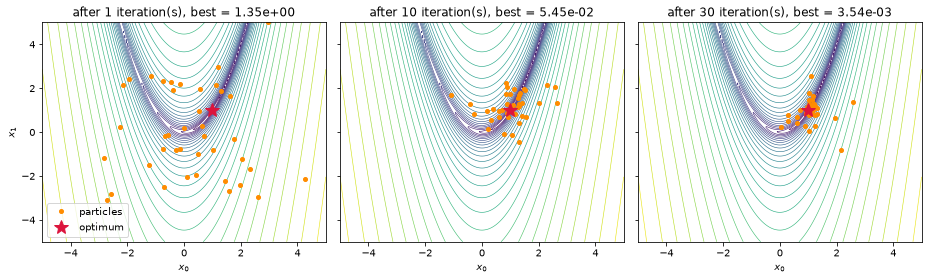

In [3]:
import numpy as np
import matplotlib.pyplot as plt

X, Y = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-5, 5, 200))
Z = rosenbrock([X, Y])

pso = PSO(rosenbrock, ranges, minimize=True, seed=0)
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True, dpi=72)
done = 0
for ax, n in zip(axes, [1, 10, 30]):
    pso.evolve(n - done)
    done = n
    ax.contour(X, Y, np.log1p(Z), levels=30, cmap="viridis", linewidths=0.6)
    ax.plot(*pso.phenotypes.T, "o", color="darkorange", ms=4, label="particles")
    ax.plot(1, 1, "*", color="crimson", ms=14, label="optimum")
    ax.set_title(f"after {n} iteration(s), best = {pso.champion.fitness:.2e}")
    ax.set_xlabel("$x_0$")
axes[0].set_ylabel("$x_1$")
axes[0].legend(loc="lower left")
plt.tight_layout()

### Evaluating the objective efficiently

By default the objective is called once per particle with a 1d array. If your objective can process a whole batch of points at once, pass `vectorized=True`: it will then receive a `(nPop, dim)` array and must return one value per row. For expensive objectives that can't be vectorized, `n_jobs` evaluates the particles in parallel processes (`-1` uses all CPUs). Note that the objective must be picklable then, i.e. a module-level function, not a lambda. You can also pass a symbolic {py:class}`~sigmaepsilon.math.function.function.Function`. All of this works exactly as for the [genetic algorithms](ga_performance.ipynb).

In [4]:
def rosenbrock_batch(x, a=1.0, b=100.0):
    return (a - x[:, 0]) ** 2 + b * (x[:, 1] - x[:, 0] ** 2) ** 2


pso = PSO(rosenbrock_batch, ranges, minimize=True, vectorized=True, seed=0)
champion = pso.solve()
champion.phenotype, champion.fitness

([1.000276368509912, 1.0005557834177625], 7.72616541917534e-08)

The result is identical to the first run, because the same seed produces the same random numbers. Only the way the objective is called has changed.

(user_guide_optimization_pso_multiple)=
## Multiple solutions

Many practical problems have several good local optima. Knowing them is valuable in its own right, e.g. to choose between alternative designs using criteria the objective doesn't capture, or to check how unique the best design is. Running a global-best PSO $k$ times doesn't help much: most runs end up in the same, most attractive basin, and you get the same solution several times.

Set `n_solutions` to the number of optima you are interested in. With `n_solutions > 1`, the optimizer does two things differently.

**During the search**, it switches to the *species-based PSO* of Li (2004). In every iteration, the personal bests are sorted from best to worst and grouped into *species*:

1. the best personal best becomes the *seed* of the first species,
2. every further personal best joins the species of the first (best) seed within `niche_radius` of it, or becomes the seed of a new species if there is none.

Every particle is then attracted by the seed of its own species instead of the global best. Particles in different basins don't pull each other away, so several basins stay populated and converge in parallel.

**At the end**, the `solutions` property picks at most `n_solutions` points from the personal bests that represent *different* optima. It visits them from best to worst and accepts a point only if:

* it is farther than `niche_radius` from every point accepted so far, **and**
* the *hill-valley test* (Ursem, 1999) finds a barrier between it and every accepted point. The objective is evaluated at a few points of the segment joining the two candidates. If none of them is worse than both endpoints, the two points lie in the same basin, so the worse one is discarded as a duplicate.

The distance criterion alone would accept a point on the slope of an already found basin if it is far enough away. The hill-valley test catches such cases, so **the same optimum is never returned twice**. If fewer distinct optima were found than requested, the list is simply shorter. The first solution is always the champion.

`niche_radius` is measured in a normalized space where every variable is scaled to $[0, 1]$ and the diagonal of the box has length 1, so its default of 0.1 is independent of the units and the number of variables. It should be smaller than the distance between the optima you want to separate, but not so small that one basin is split into many species.

Let's try it on Himmelblau's function, which has four minima of equal value $0$:

In [5]:
def himmelblau(x):
    return (x[0] ** 2 + x[1] - 11) ** 2 + (x[0] + x[1] ** 2 - 7) ** 2


pso = PSO(himmelblau, ranges, nPop=60, minimize=True, n_solutions=4, seed=0)
champion = pso.solve()
[(np.round(s.phenotype, 4).tolist(), s.fitness) for s in pso.solutions]

[([3.0, 2.0], 2.85415404679223e-19),
 ([-3.7793, -3.2832], 4.995895211369592e-19),
 ([-2.8051, 3.1313], 1.4549069588678043e-18),
 ([3.5844, -1.8481], 2.48513850222831e-18)]

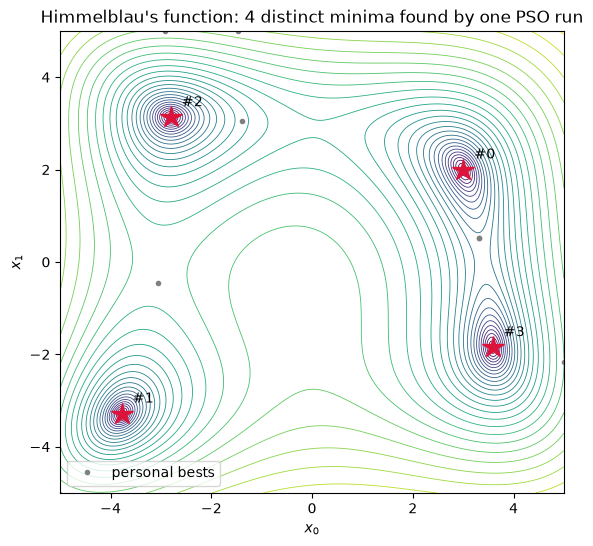

In [6]:
Z = himmelblau([X, Y])
points, _ = pso.archive()

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.contour(X, Y, np.log1p(Z), levels=30, cmap="viridis", linewidths=0.6)
ax.plot(*points.T, ".", color="gray", label="personal bests")
for i, s in enumerate(pso.solutions):
    ax.plot(*s.phenotype, "*", color="crimson", ms=16)
    ax.annotate(f"#{i}", s.phenotype, textcoords="offset points", xytext=(8, 8))
ax.set_xlabel("$x_0$")
ax.set_ylabel("$x_1$")
ax.set_title("Himmelblau's function: 4 distinct minima found by one PSO run")
ax.legend(loc="lower left");

All four minima are found in a single run. Each one is accurate to many digits, and each appears only once, even though dozens of particles converged into every basin.

Asking for more solutions than there are basins doesn't produce duplicates. The sphere function has a single minimum, so even with `n_solutions=5` we get one solution back:

In [7]:
pso = PSO(lambda x: x[0] ** 2 + x[1] ** 2, ranges, minimize=True, n_solutions=5, seed=0)
pso.solve()
[(np.round(s.phenotype, 6).tolist(), s.fitness) for s in pso.solutions]

[([-0.0, 0.0], 2.5154009752129057e-21)]

A few practical notes:

* With `n_solutions > 1`, the run only stops early once *no* personal best has improved significantly for more than `maxage` iterations, not just the champion. A niche that is still converging keeps the search alive, so expect these runs to use more of the `maxiter` budget.
* Several niches need more particles than one optimum: as a rule of thumb, aim for at least 10–15 particles per expected optimum (`nPop`).
* The hill-valley tests evaluate the objective a few more times. These evaluations are included in `state.n_fev`, and the result is cached until the next iteration.
* Optima are only found if some particles end up in their basin. Very narrow basins, or basins at the edge of the box, can be missed. More particles and a smaller `niche_radius` help.
* The hill-valley test places its points at most `niche_radius / 2` apart along the segment between two candidates, so it doesn't miss the hills even when the segment crosses other basins.

## Constraints

Box constraints are handled by `ranges`. For general equality and inequality constraints, see {doc}`penalty`, which shows how to fold them into the objective with penalties and works with PSO and DE alike.